In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn nltk wordcloud

MBA691_Project5.ipynb

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import html
import warnings

# Narrowed from a blanket filter so genuine errors stay visible
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [3]:
df = pd.read_csv("Tweets.csv")

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 14640
Columns: 15


In [4]:
df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [5]:
df.columns

Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count', 'text', 'tweet_coord', 'tweet_created',
       'tweet_location', 'user_timezone'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

In [7]:
df.describe(include="all")

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
count,1.464000e+04,14640,14640.000000,9178,10522.000000,14640,40,14640,32,14640.000000,14640,1019,14640,9907,9820
unique,NaN,3,NaN,10,NaN,6,3,7701,13,NaN,14427,832,14247,3081,85
top,NaN,negative,NaN,Customer Service Issue,NaN,United,negative,JetBlueNews,Customer Service Issue,NaN,@united thanks,"[0.0, 0.0]",2015-02-24 09:54:34 -0800,"Boston, MA",Eastern Time (US & Canada)
freq,NaN,9178,NaN,2910,NaN,3822,32,63,12,NaN,6,164,5,157,3744
mean,5.692184e+17,NaN,0.900169,NaN,0.638298,NaN,NaN,NaN,NaN,0.082650,NaN,NaN,NaN,NaN,NaN
std,7.791112e+14,NaN,0.162830,NaN,0.330440,NaN,NaN,NaN,NaN,0.745778,NaN,NaN,NaN,NaN,NaN
min,5.675883e+17,NaN,0.335000,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN
25%,5.685592e+17,NaN,0.692300,NaN,0.360600,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN
50%,5.694779e+17,NaN,1.000000,NaN,0.670600,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN
75%,5.698905e+17,NaN,1.000000,NaN,1.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN


checking missing values

In [8]:
df.isnull().sum()

,0
tweet_id,0
airline_sentiment,0
airline_sentiment_confidence,0
negativereason,5462
negativereason_confidence,4118
airline,0
airline_sentiment_gold,14600
name,0
negativereason_gold,14608
retweet_count,0


duplicate tweets

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 36


sentiments checking

In [10]:
df["airline_sentiment"].value_counts()

,count
airline_sentiment,
negative,9178
neutral,3099
positive,2363


checking airlines

In [11]:
df["airline"].value_counts()

,count
airline,
United,3822
US Airways,2913
American,2759
Southwest,2420
Delta,2222
Virgin America,504


**data quality summary**

In [12]:
data_quality = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isnull().sum().values,
    "Unique Values": df.nunique().values
})

data_quality

,Column,Data Type,Missing Values,Unique Values
0,tweet_id,int64,0,14485
1,airline_sentiment,object,0,3
2,airline_sentiment_confidence,float64,0,1023
3,negativereason,object,5462,10
4,negativereason_confidence,float64,4118,1410
5,airline,object,0,6
6,airline_sentiment_gold,object,14600,3
7,name,object,0,7701
8,negativereason_gold,object,14608,13
9,retweet_count,int64,0,18


In [13]:
import os

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)
os.makedirs("models", exist_ok=True)

In [14]:
data_quality.to_csv(
    "outputs/tables/data_quality.csv",
    index=False
)

**data cleaning**

In [15]:
def clean_text(text):

    # Convert to string
    text = str(text)

    # Decode HTML entities (&amp; &lt; &gt; &quot;) before stripping symbols,
    # otherwise "&amp;" survives as the junk token "amp"
    text = html.unescape(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove mentions
    text = re.sub(r"@\w+", "", text)

    # Remove hashtag symbol but keep hashtag word
    text = re.sub(r"#", "", text)

    # Remove RT
    text = re.sub(r"\brt\b", "", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [16]:
df["clean_text"] = df["text"].apply(clean_text)

In [17]:
df[["text", "clean_text"]].head(10)

,text,clean_text
0,@VirginAmerica What @dhepburn said.,what said
1,@VirginAmerica plus you've added commercials t...,plus you ve added commercials to the experienc...
2,@VirginAmerica I didn't today... Must mean I n...,i didn t today must mean i need to take anothe...
3,@VirginAmerica it's really aggressive to blast...,it s really aggressive to blast obnoxious ente...
4,@VirginAmerica and it's a really big bad thing...,and it s a really big bad thing about it
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay a flight for seats that di...
6,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time i fly vx this ear worm w...
7,@VirginAmerica Really missed a prime opportuni...,really missed a prime opportunity for men with...
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",well i didn t but now i do d
9,"@VirginAmerica it was amazing, and arrived an ...",it was amazing and arrived an hour early you r...


**removing duplicates and missing values**

In [18]:
print("Before cleaning:", len(df))

df = df.drop_duplicates(subset=["text"])

df = df.dropna(subset=["text", "airline_sentiment"])

print("After cleaning:", len(df))

Before cleaning: 14640
After cleaning: 14427


In [19]:
df = df.reset_index(drop=True)

**Data quality check after cleaning**

In [20]:
# Data-quality diagnostic for the limitations section.
# Deduplication above is on raw "text". Cleaning strips @mentions, so tweets that
# differed only by the airline handle collapse to identical clean_text.
residual = df["clean_text"].duplicated().sum()
print("Rows after dedup on raw text:", len(df))
print("Residual duplicate clean_text rows:", residual)
print("Empty clean_text rows:", (df["clean_text"].str.len() == 0).sum())

# To dedupe on the cleaned text instead, uncomment the next two lines and rerun
# from here. Note this changes every downstream metric, including DistilBERT.
# df = df.drop_duplicates(subset=["clean_text"]).reset_index(drop=True)
# print("Rows after dedup on clean_text:", len(df))

Rows after dedup on raw text: 14427
Residual duplicate clean_text rows: 260
Empty clean_text rows: 0


**checking sentiment table**

In [21]:
sentiment_counts = df["airline_sentiment"].value_counts()

print(sentiment_counts)

airline_sentiment
negative    9080
neutral     3057
positive    2290
Name: count, dtype: int64


In [22]:
sentiment_percentage = (
    df["airline_sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(sentiment_percentage)

airline_sentiment
negative    62.94
neutral     21.19
positive    15.87
Name: proportion, dtype: float64


In [23]:
sentiment_summary = pd.DataFrame({
    "Count": sentiment_counts,
    "Percentage": sentiment_percentage
})

sentiment_summary

,Count,Percentage
airline_sentiment,,
negative,9080,62.94
neutral,3057,21.19
positive,2290,15.87


**EDA: Sentiment distribution**

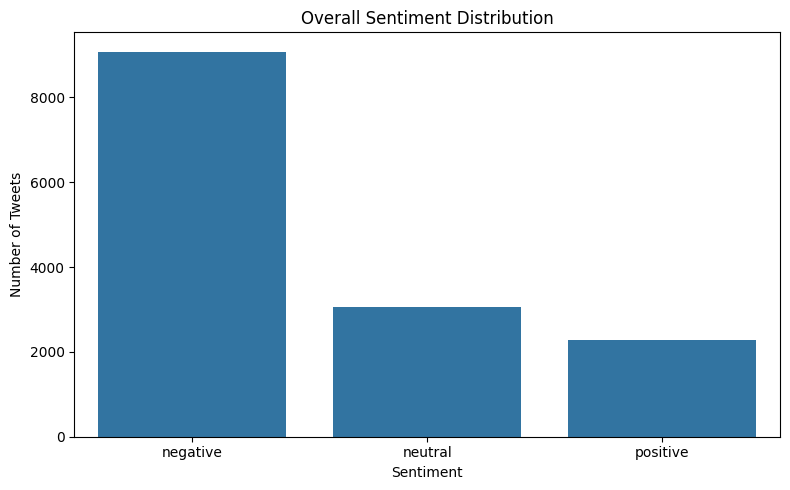

In [24]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="airline_sentiment",
    order=["negative", "neutral", "positive"]
)

plt.title("Overall Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.tight_layout()

plt.savefig(
    "outputs/figures/overall_sentiment.png",
    dpi=300
)

plt.show()

**sentiment by airline**

In [25]:
airline_sentiment = pd.crosstab(
    df["airline"],
    df["airline_sentiment"]
)

airline_sentiment

airline_sentiment,negative,neutral,positive
airline,,,
American,1864,431,299
Delta,955,723,533
Southwest,1185,658,565
US Airways,2262,380,264
United,2633,694,478
Virgin America,181,171,151


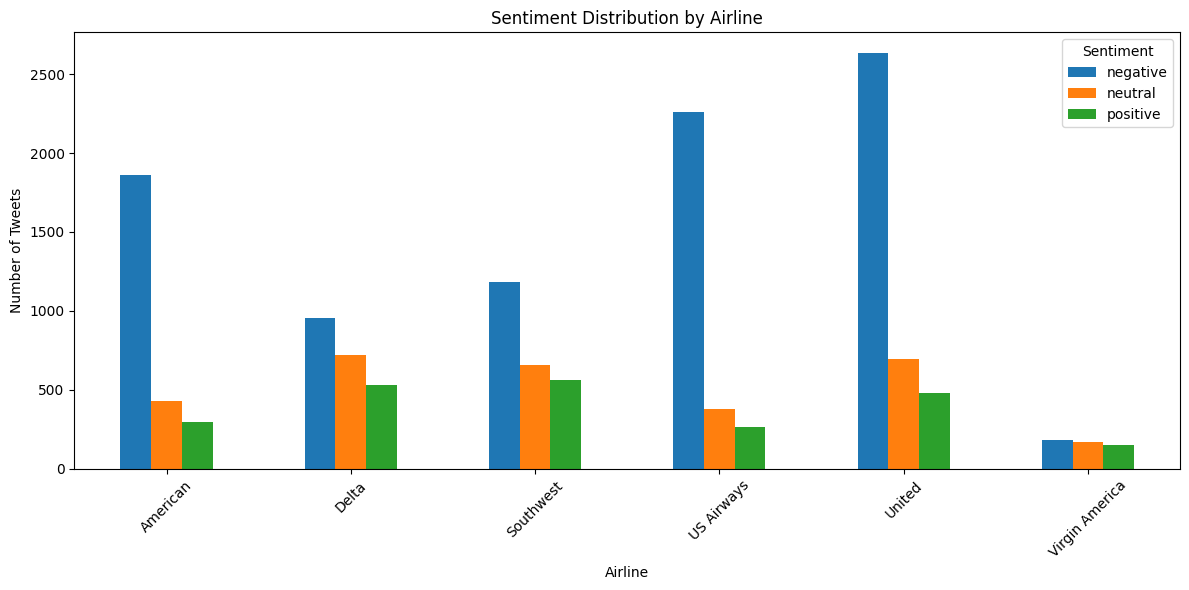

In [26]:
airline_sentiment.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Sentiment Distribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.tight_layout()

plt.savefig(
    "outputs/figures/sentiment_by_airline.png",
    dpi=300
)

plt.show()

**Sentiment percentage by airline**

In [27]:
airline_sentiment_percentage = pd.crosstab(
    df["airline"],
    df["airline_sentiment"],
    normalize="index"
) * 100

airline_sentiment_percentage.round(2)

airline_sentiment,negative,neutral,positive
airline,,,
American,71.86,16.62,11.53
Delta,43.19,32.70,24.11
Southwest,49.21,27.33,23.46
US Airways,77.84,13.08,9.08
United,69.20,18.24,12.56
Virgin America,35.98,34.00,30.02


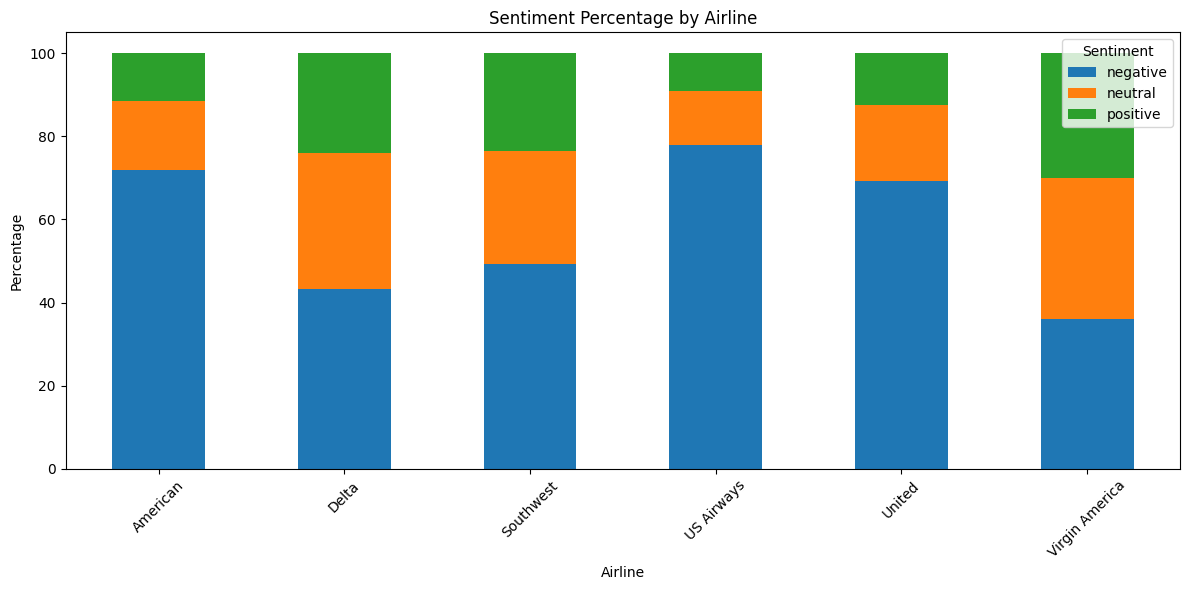

In [28]:
airline_sentiment_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)

plt.title("Sentiment Percentage by Airline")
plt.xlabel("Airline")
plt.ylabel("Percentage")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.tight_layout()

plt.savefig(
    "outputs/figures/sentiment_percentage_airline.png",
    dpi=300
)

plt.show()

**Negative complaint analysis**

In [29]:
negative_df = df[
    df["airline_sentiment"] == "negative"
].copy()

In [30]:
negative_reasons = (
    negative_df["negativereason"]
    .value_counts()
)

negative_reasons

,count
negativereason,
Customer Service Issue,2883
Late Flight,1650
Can't Tell,1176
Cancelled Flight,829
Lost Luggage,719
Bad Flight,575
Flight Booking Problems,523
Flight Attendant Complaints,475
longlines,177


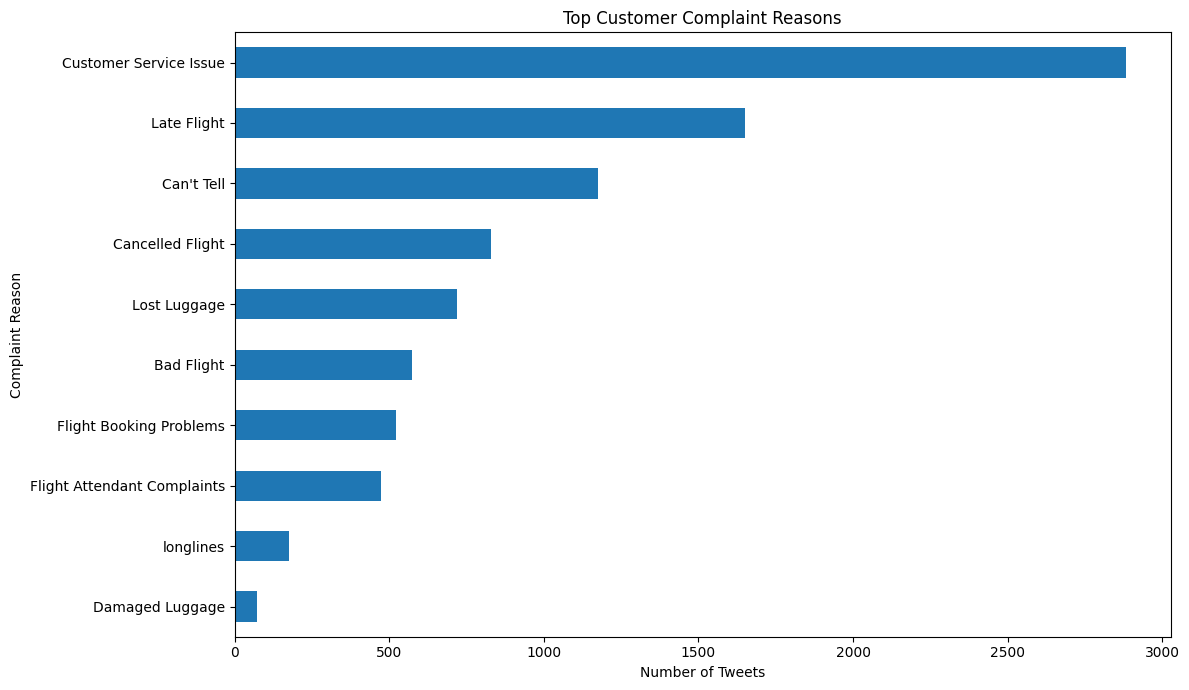

In [31]:
plt.figure(figsize=(12,7))

negative_reasons.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top Customer Complaint Reasons")
plt.xlabel("Number of Tweets")
plt.ylabel("Complaint Reason")
plt.tight_layout()

plt.savefig(
    "outputs/figures/top_complaints.png",
    dpi=300
)

plt.show()

**complaint percentage**

In [32]:
complaint_percentage = (
    negative_df["negativereason"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

complaint_summary = pd.DataFrame({
    "Count": negative_reasons,
    "Percentage": complaint_percentage
})

complaint_summary

,Count,Percentage
negativereason,,
Customer Service Issue,2883,31.75
Late Flight,1650,18.17
Can't Tell,1176,12.95
Cancelled Flight,829,9.13
Lost Luggage,719,7.92
Bad Flight,575,6.33
Flight Booking Problems,523,5.76
Flight Attendant Complaints,475,5.23
longlines,177,1.95


In [33]:
complaint_summary.to_csv(
    "outputs/tables/complaint_summary.csv"
)

**Complaint reasons by airline**

In [34]:
complaints_airline = pd.crosstab(
    negative_df["airline"],
    negative_df["negativereason"]
)

complaints_airline

negativereason,Bad Flight,Can't Tell,Cancelled Flight,Customer Service Issue,Damaged Luggage,Flight Attendant Complaints,Flight Booking Problems,Late Flight,Lost Luggage,longlines
airline,,,,,,,,,,
American,82,184,228,743,11,81,124,234,144,33
Delta,64,186,51,199,11,60,44,269,57,14
Southwest,90,159,162,390,14,38,61,152,90,29
US Airways,104,246,189,810,11,123,122,453,154,50
United,216,379,181,681,22,168,144,525,269,48
Virgin America,19,22,18,60,4,5,28,17,5,3


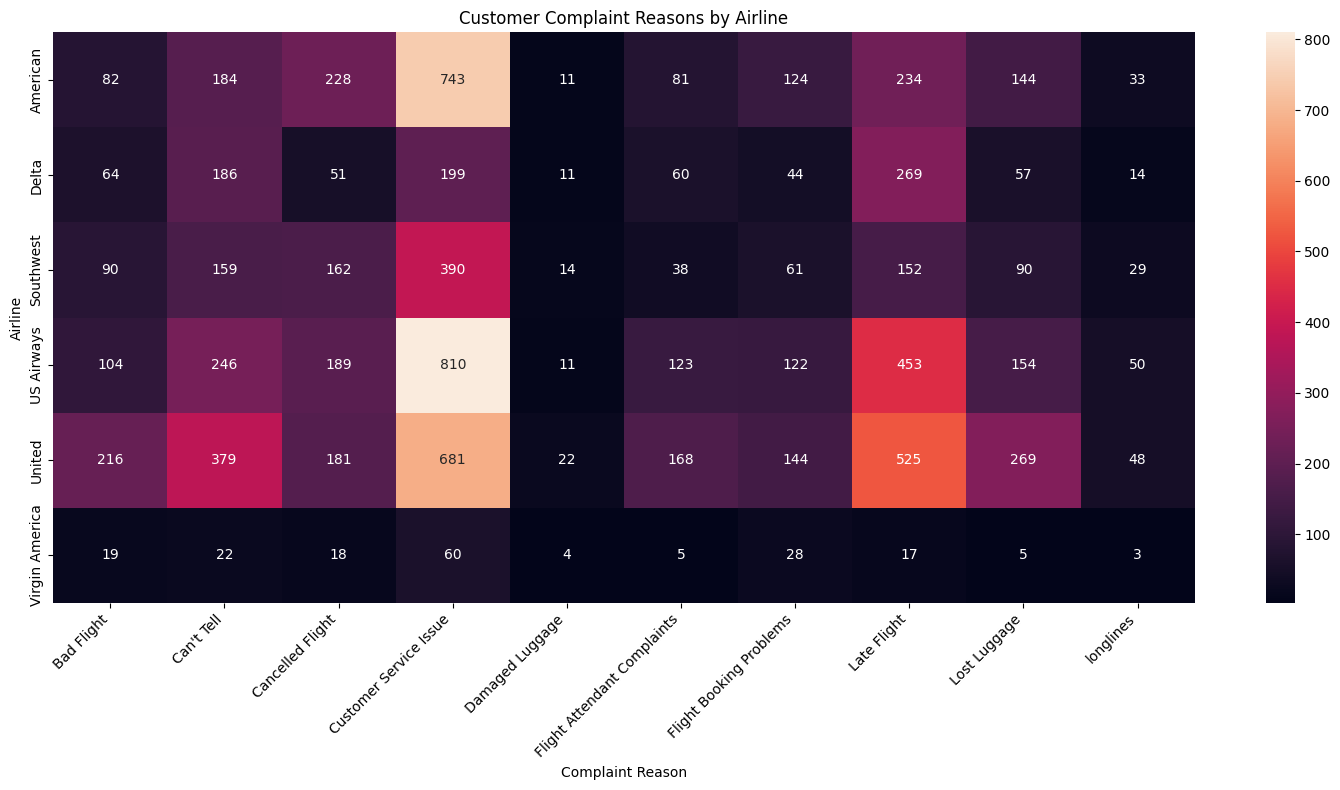

In [35]:
plt.figure(figsize=(15,8))

sns.heatmap(
    complaints_airline,
    annot=True,
    fmt="d"
)

plt.title("Customer Complaint Reasons by Airline")
plt.xlabel("Complaint Reason")
plt.ylabel("Airline")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "outputs/figures/complaints_by_airline.png",
    dpi=300
)

plt.show()

**most common words**

In [36]:
import nltk

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [37]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

In [38]:
words = " ".join(df["clean_text"]).split()

filtered_words = [
    word for word in words
    if word not in stop_words and len(word) > 2
]

word_frequency = pd.Series(filtered_words).value_counts()

word_frequency.head(20)

,count
flight,3905
get,1333
cancelled,1043
thanks,1041
service,959
help,864
time,786
customer,750
hours,676
flights,644


**word cloud**

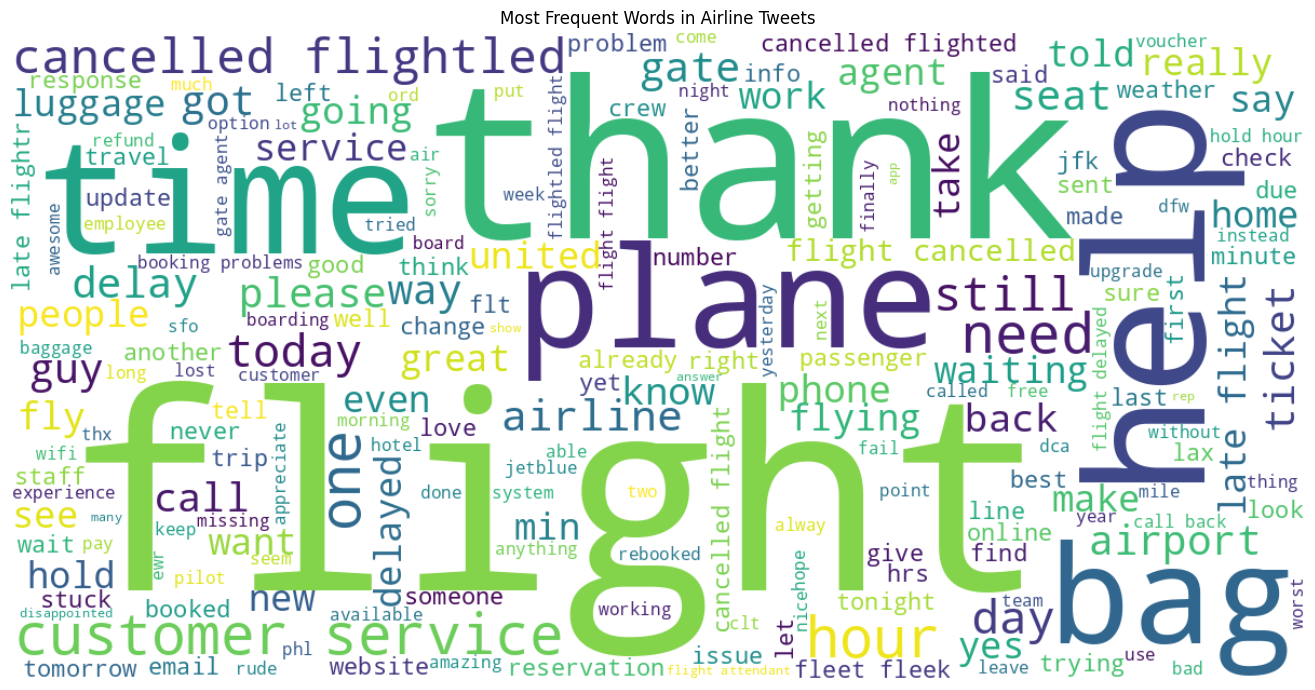

In [39]:
from wordcloud import WordCloud

text_for_wordcloud = " ".join(filtered_words)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white"
).generate(text_for_wordcloud)

plt.figure(figsize=(15,7))

plt.imshow(wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title("Most Frequent Words in Airline Tweets")

plt.tight_layout()

plt.savefig(
    "outputs/figures/wordcloud.png",
    dpi=300
)

plt.show()

**sentiment over time**

In [40]:
df["tweet_created"] = pd.to_datetime(
    df["tweet_created"],
    errors="coerce"
)

In [41]:
daily_sentiment = (
    df.groupby([
        df["tweet_created"].dt.date,
        "airline_sentiment"
    ])
    .size()
    .unstack(fill_value=0)
)

daily_sentiment.head()

airline_sentiment,negative,neutral,positive
tweet_created,,,
2015-02-16,3,1,0
2015-02-17,838,294,267
2015-02-18,736,333,265
2015-02-19,751,327,289
2015-02-20,835,381,276


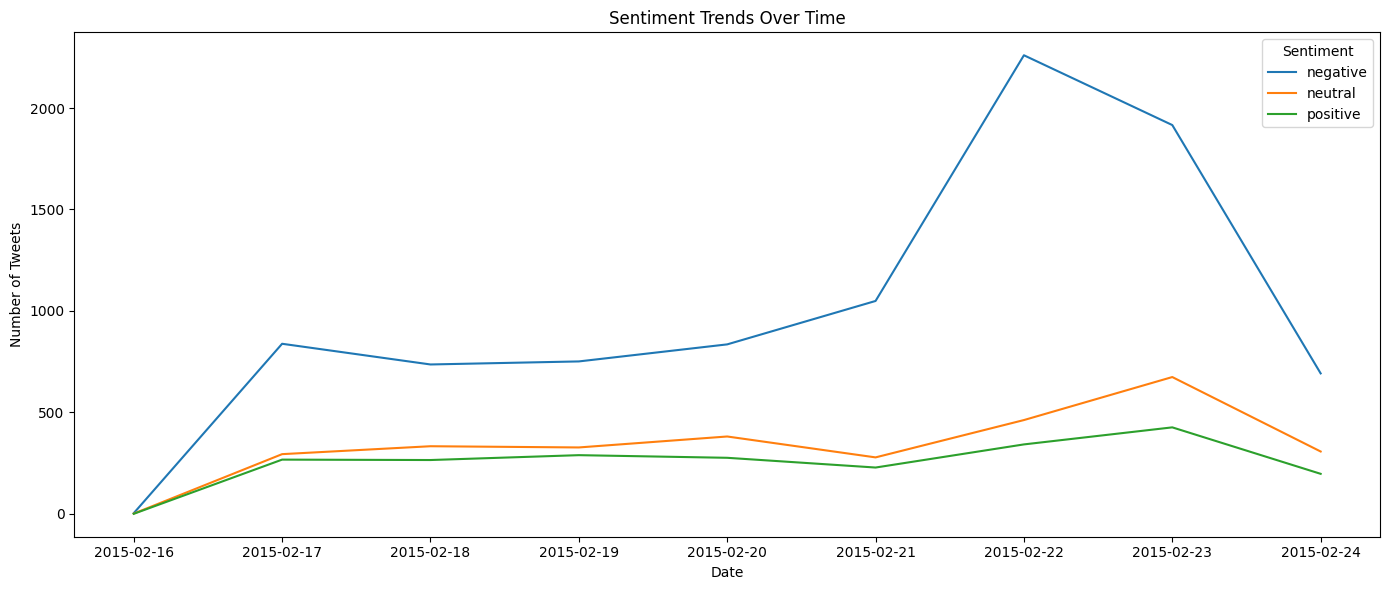

In [42]:
daily_sentiment.plot(
    figsize=(14,6)
)

plt.title("Sentiment Trends Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Tweets")
plt.legend(title="Sentiment")
plt.tight_layout()

plt.savefig(
    "outputs/figures/sentiment_over_time.png",
    dpi=300
)

plt.show()

**Preparing machine-learning data**

In [43]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["airline_sentiment"]

first split

In [44]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

second split

In [45]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [46]:
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nPercentages:")

print(
    "Training:",
    round(len(X_train) / len(df) * 100, 2),
    "%"
)

print(
    "Validation:",
    round(len(X_val) / len(df) * 100, 2),
    "%"
)

print(
    "Testing:",
    round(len(X_test) / len(df) * 100, 2),
    "%"
)

Training: 11541
Validation: 1443
Testing: 1443

Percentages:
Training: 80.0 %
Validation: 10.0 %
Testing: 10.0 %


**TD-IDF**

In [47]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

In [48]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_val_tfidf = tfidf.transform(X_val)

X_test_tfidf = tfidf.transform(X_test)

In [49]:
print("Training shape:", X_train_tfidf.shape)
print("Validation shape:", X_val_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (11541, 10000)
Validation shape: (1443, 10000)
Testing shape: (1443, 10000)


In [50]:
# Quantify train/test contamination introduced by cleaning
overlap = len(set(X_train) & set(X_test))
print("Identical cleaned strings appearing in both train and test:", overlap)
print("As a share of the test set:", round(overlap / len(X_test) * 100, 2), "%")

Identical cleaned strings appearing in both train and test: 23
As a share of the test set: 1.59 %


**Logistic Regression baseline**

In [51]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_tfidf,
    y_train
)

LogisticRegression(max_iter=1000, random_state=42)

validation prediction

In [52]:
y_val_pred = logistic_model.predict(X_val_tfidf)

**tuning the baseline model**

In [53]:
from sklearn.model_selection import GridSearchCV

parameters = {
    "C": [0.1, 0.5, 1, 2, 5],
    "class_weight": [None, "balanced"]
}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000),
    parameters,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid.fit(
    X_train_tfidf,
    y_train
)

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000), n_jobs=-1,
             param_grid={'C': [0.1, 0.5, 1, 2, 5],
                         'class_weight': [None, 'balanced']},
             scoring='f1_macro')

In [54]:
best_logistic = grid.best_estimator_

print("Best Parameters:")
print(grid.best_params_)

Best Parameters:
{'C': 0.5, 'class_weight': 'balanced'}


**evaluating logistic regression**

In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_test_pred = best_logistic.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_test_pred)

precision = precision_score(
    y_test,
    y_test_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_test_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_test_pred,
    average="weighted"
)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Accuracy: 0.7755
Precision: 0.7947
Recall: 0.7755
F1 Score: 0.7819


**detailed report**

**confusion matrix**

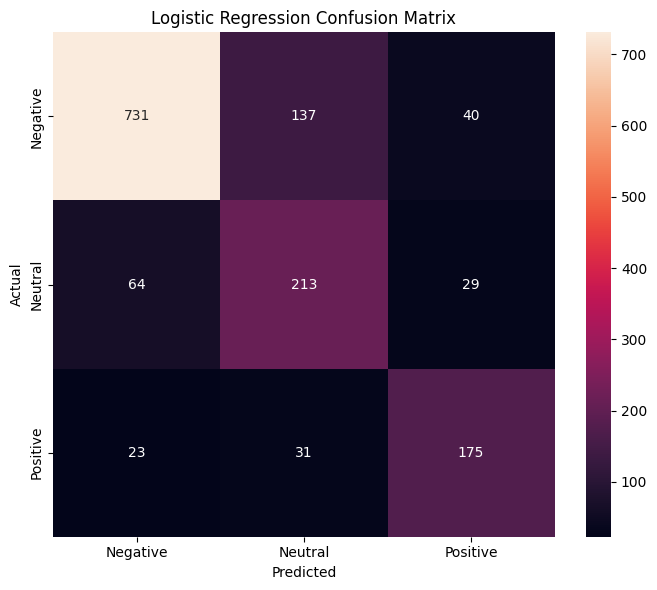

In [56]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=["negative", "neutral", "positive"]
)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "outputs/figures/logistic_confusion_matrix.png",
    dpi=300
)

plt.show()

In [57]:
from sklearn.metrics import classification_report

# Classification report
report = classification_report(
    y_test,
    y_test_pred,
    target_names=["Negative", "Neutral", "Positive"],
    digits=4
)

print(report)

              precision    recall  f1-score   support

    Negative     0.8936    0.8051    0.8470       908
     Neutral     0.5591    0.6961    0.6201       306
    Positive     0.7172    0.7642    0.7400       229

    accuracy                         0.7755      1443
   macro avg     0.7233    0.7551    0.7357      1443
weighted avg     0.7947    0.7755    0.7819      1443



**Logistic Regression ROC-AUC**

In [58]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

lr_probabilities = best_logistic.predict_proba(X_test_tfidf)

lr_roc_auc = roc_auc_score(
    label_binarize(y_test, classes=list(best_logistic.classes_)),
    lr_probabilities,
    multi_class="ovr",
    average="weighted"
)

lr_f1_macro = f1_score(y_test, y_test_pred, average="macro")

print("Logistic Regression weighted ROC-AUC:", round(lr_roc_auc, 4))
print("Logistic Regression macro F1:", round(lr_f1_macro, 4))

Logistic Regression weighted ROC-AUC: 0.9021
Logistic Regression macro F1: 0.7357


**Naïve Bayes comparison**

In [59]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(
    X_train_tfidf,
    y_train
)

nb_pred = nb_model.predict(
    X_test_tfidf
)

In [60]:
nb_accuracy = accuracy_score(
    y_test,
    nb_pred
)

nb_precision = precision_score(
    y_test,
    nb_pred,
    average="weighted"
)

nb_recall = recall_score(
    y_test,
    nb_pred,
    average="weighted"
)

nb_f1 = f1_score(
    y_test,
    nb_pred,
    average="weighted"
)

print("Naive Bayes Accuracy:", nb_accuracy)
print("Naive Bayes Precision:", nb_precision)
print("Naive Bayes Recall:", nb_recall)
print("Naive Bayes F1:", nb_f1)

Naive Bayes Accuracy: 0.7352737352737353
Naive Bayes Precision: 0.7646535700631371
Naive Bayes Recall: 0.7352737352737353
Naive Bayes F1: 0.6864468957850712


In [61]:
nb_f1_macro = f1_score(y_test, nb_pred, average="macro")

print("Naive Bayes macro F1:", round(nb_f1_macro, 4))

Naive Bayes macro F1: 0.5779


**model comparison table**

In [62]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes"
    ],

    "Accuracy": [
        accuracy,
        nb_accuracy
    ],

    "Precision": [
        precision,
        nb_precision
    ],

    "Recall": [
        recall,
        nb_recall
    ],

    "F1 Score": [
        f1,
        nb_f1
    ]
})

model_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7755,0.7947,0.7755,0.7819
1,Naive Bayes,0.7353,0.7647,0.7353,0.6864


In [63]:
model_results.to_csv(
    "outputs/tables/baseline_model_comparison.csv",
    index=False
)

**transformer model**

In [64]:
!pip install transformers datasets accelerate evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.9 MB/s eta 0:00:00


In [65]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

from datasets import Dataset

creating table

In [66]:
label_mapping = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

df["label"] = df["airline_sentiment"].map(label_mapping)

transformer dataset

In [67]:
train_df = df.loc[X_train.index][
    ["clean_text", "label"]
].copy()

val_df = df.loc[X_val.index][
    ["clean_text", "label"]
].copy()

test_df = df.loc[X_test.index][
    ["clean_text", "label"]
].copy()

In [68]:
train_dataset = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df,
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df,
    preserve_index=False
)

**loading DistilBERT**

In [69]:
model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    model_name
)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

tokenization

In [70]:
def tokenize_function(examples):
    return tokenizer(
        examples["clean_text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

In [71]:
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

Map:   0%|          | 0/11541 [00:00<?, ? examples/s]

Map:   0%|          | 0/1443 [00:00<?, ? examples/s]

Map:   0%|          | 0/1443 [00:00<?, ? examples/s]

In [72]:
transformer_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


**Transformer evaluation metrics**

In [73]:
import evaluate

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")

In [74]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    accuracy = accuracy_metric.compute(
        predictions=predictions,
        references=labels
    )["accuracy"]

    f1 = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average="weighted"
    )["f1"]

    precision = precision_metric.compute(
        predictions=predictions,
        references=labels,
        average="weighted"
    )["precision"]

    recall = recall_metric.compute(
        predictions=predictions,
        references=labels,
        average="weighted"
    )["recall"]

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

**Training DistilBERT**

In [75]:
training_args = TrainingArguments(
    output_dir="./models/distilbert",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none"
)

**Creating the Trainer**

In [76]:
trainer = Trainer(
    model=transformer_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

**Fine-tuning DistilBERT**

In [77]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.567711,0.436328,0.837145,0.837725,0.837145,0.837271
2,0.397024,0.454661,0.839917,0.834775,0.839917,0.834714
3,0.249580,0.510075,0.842689,0.840702,0.842689,0.841196


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2166, training_loss=0.3725739951939464, metrics={'train_runtime': 453.2904, 'train_samples_per_second': 76.382, 'train_steps_per_second': 4.778, 'total_flos': 1146625133983488.0, 'train_loss': 0.3725739951939464, 'epoch': 3.0})

**Testing DistilBERT**

In [78]:
transformer_results = trainer.evaluate(
    test_dataset
)

transformer_results

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.249580,0.529032,3,0.837145,0.835142,0.837145,0.835918


{'eval_loss': 0.5290320515632629,
 'eval_accuracy': 0.8371448371448371,
 'eval_precision': 0.835142197493495,
 'eval_recall': 0.8371448371448371,
 'eval_f1': 0.8359176136082535}

**DistilBERT predictions and ROC-AUC (after training)**

In [106]:
# Predictions are generated AFTER trainer.train() so they come from the
# fine-tuned model. Running this before training returns a random head.
pred_output = trainer.predict(test_dataset)

y_pred = pred_output.predictions.argmax(axis=1)
y_true = pred_output.label_ids

print("Prediction scores shape:", pred_output.predictions.shape)
print("Predictions:", y_pred[:10])
print("Actual labels:", y_true[:10])
print("Number of predictions:", len(y_pred))

Prediction scores shape: (1443, 3)
Predictions: [0 1 0 0 2 1 0 2 0 0]
Actual labels: [2 1 0 0 2 1 0 2 0 0]
Number of predictions: 1443


In [113]:
from sklearn.metrics import roc_auc_score

# Convert logits to probabilities with a numerically stable softmax
scores = pred_output.predictions
exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
probabilities = exp_scores / exp_scores.sum(axis=1, keepdims=True)

transformer_roc_auc = roc_auc_score(
    y_true,
    probabilities,
    multi_class="ovr",
    average = "weighted"
)

transformer_f1_macro = f1_score(y_true, y_pred, average="macro")

print("DistilBERT weighted ROC-AUC:", round(transformer_roc_auc, 4))
print("DistilBERT macro F1:", round(transformer_f1_macro, 4))

DistilBERT weighted ROC-AUC: 0.9285
DistilBERT macro F1: 0.7897


In [114]:
per_class_auc = roc_auc_score(
    y_true,
    probabilities,
    multi_class="ovr",
    average=None
)

for name, score in zip(["negative", "neutral", "positive"], per_class_auc):
    print(f"DistilBERT AUC {name}: {round(score, 4)}")

DistilBERT AUC negative: 0.9333
DistilBERT AUC neutral: 0.8966
DistilBERT AUC positive: 0.9522


**final model comparison**

In [81]:
final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "DistilBERT"
    ],

    "Accuracy": [
        accuracy,
        nb_accuracy,
        transformer_results["eval_accuracy"]
    ],

    "Precision (weighted)": [
        precision,
        nb_precision,
        transformer_results["eval_precision"]
    ],

    "Recall (weighted)": [
        recall,
        nb_recall,
        transformer_results["eval_recall"]
    ],

    "F1 (weighted)": [
        f1,
        nb_f1,
        transformer_results["eval_f1"]
    ],

    # Macro F1 is the honest headline on a 63/21/16 class split.
    # Weighted F1 is inflated by the dominant negative class.
    "F1 (macro)": [
        lr_f1_macro,
        nb_f1_macro,
        transformer_f1_macro
    ],

    "ROC-AUC (weighted OvR)": [
        lr_roc_auc,
        np.nan,
        transformer_roc_auc
    ]
})

final_results.round(4)

,Model,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),F1 (macro),ROC-AUC (weighted OvR)
0,Logistic Regression,0.7755,0.7947,0.7755,0.7819,0.7357,0.9021
1,Naive Bayes,0.7353,0.7647,0.7353,0.6864,0.5779,NaN
2,DistilBERT,0.8371,0.8351,0.8371,0.8359,0.7897,0.9285


In [82]:
final_results.to_csv(
    "outputs/tables/final_model_comparison.csv",
    index=False
)

**Persisting the classical models**

In [83]:
import joblib

joblib.dump(tfidf, "models/tfidf_vectorizer.joblib")
joblib.dump(best_logistic, "models/logistic_regression.joblib")

print("TF-IDF vectorizer and tuned logistic regression saved to models/")

TF-IDF vectorizer and tuned logistic regression saved to models/


**Topic modelling with BERTopic**

In [84]:
!pip install bertopic sentence-transformers umap-learn hdbscan

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 8.0 MB/s eta 0:00:00


In [85]:
from bertopic import BERTopic

**using negative tweets**

In [86]:
topic_documents = negative_df["clean_text"].tolist()

In [87]:
from umap import UMAP
from sklearn.feature_extraction.text import CountVectorizer

# random_state makes UMAP deterministic, otherwise topics differ on every run
umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=42
)

# stop words are removed from the topic *labels* only, not the embeddings
topic_vectorizer = CountVectorizer(stop_words="english")

topic_model = BERTopic(
    umap_model=umap_model,
    vectorizer_model=topic_vectorizer,
    calculate_probabilities=False
)

topics, probabilities = topic_model.fit_transform(
    topic_documents
)

print("Documents:", len(topic_documents))
print("Topics found:", len(set(topics)) - (1 if -1 in topics else 0))
print("Outliers (topic -1):", topics.count(-1) if isinstance(topics, list) else (topics == -1).sum())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Documents: 9080
Topics found: 102
Outliers (topic -1): 3778


view topics

In [88]:
topic_info = topic_model.get_topic_info()

topic_info.head(15)

,Topic,Count,Name,Representation,Representative_Docs
0,-1,3778,-1_flight_service_cancelled_plane,"[flight, service, cancelled, plane, customer, ...",[got an email about an itinerary change but ca...
1,0,874,0_bag_bags_luggage_baggage,"[bag, bags, luggage, baggage, lost, claim, che...",[where are my bags baggage claim c or c flt i ...
2,1,238,1_gate_agent_waiting_sitting,"[gate, agent, waiting, sitting, gates, tarmac,...",[how can u not have gate ready or gate agent f...
3,2,235,2_seat_seats_class_row,"[seat, seats, class, row, window, upgrade, pai...",[i am in seat c and i cannot even open my lapt...
4,3,159,3_united_unitedairlines_airlines_unitedfail,"[united, unitedairlines, airlines, unitedfail,...",[never flying united again worst experience ev...
5,4,131,4_delayed_delay_delays_flight,"[delayed, delay, delays, flight, time, late, f...","[flight it s been delayed every hour since am,..."
6,5,120,5_food_catering_meal_drink,"[food, catering, meal, drink, coffee, drinks, ...",[flight attendants on aa were spectacular fed ...
7,6,115,6_hold_rebook_cancelled_flightled,"[hold, rebook, cancelled, flightled, hours, mi...",[on hold minutes trying to rebook cancelled fl...
8,7,115,7_reservation_reservations_hold_online,"[reservation, reservations, hold, online, phon...","[minutes on hold for a reservation, i ve been ..."
9,8,113,8_cancelled_flightled_flighted_flight,"[cancelled, flightled, flighted, flight, shv, ...",[flight was cancelled flightled can you guys h...


viewing topic word

In [89]:
for topic_id in topic_info["Topic"].head(10):

    if topic_id != -1:
        print(
            "Topic:",
            topic_id
        )

        print(
            topic_model.get_topic(topic_id)
        )

        print("-" * 50)

Topic: 0
[('bag', np.float64(0.04663758402140065)), ('bags', np.float64(0.038874534643334374)), ('luggage', np.float64(0.03807440836968185)), ('baggage', np.float64(0.030104608900369232)), ('lost', np.float64(0.022684894448398895)), ('claim', np.float64(0.01613989599137792)), ('checked', np.float64(0.013440849856379694)), ('clothes', np.float64(0.011258418229242522)), ('check', np.float64(0.010473496608013314)), ('carry', np.float64(0.00965007276792216))]
--------------------------------------------------
Topic: 1
[('gate', np.float64(0.11657707066448207)), ('agent', np.float64(0.03110409981587126)), ('waiting', np.float64(0.019877586211334803)), ('sitting', np.float64(0.01819484072025523)), ('gates', np.float64(0.017196029577043796)), ('tarmac', np.float64(0.017168537007792275)), ('min', np.float64(0.015821494750247862)), ('agents', np.float64(0.015482070618157241)), ('minutes', np.float64(0.012236852341214586)), ('plane', np.float64(0.012164426888253553))]
---------------------------

**topic visualization**

In [90]:
topic_model.visualize_barchart(
    top_n_topics=10
)

In [91]:
topic_model.visualize_topics()

**SHAP explainability**

In [92]:
!pip install shap

In [93]:
import shap

**Creating a prediction function:**

In [94]:
def predict_probability(texts):

    transformed = tfidf.transform(texts)

    return best_logistic.predict_proba(
        transformed
    )

In [95]:
import re

class CustomSHAPTokenizer:
    def __init__(self, tfidf_vectorizer):
        self.tfidf_vectorizer = tfidf_vectorizer
        # Get the token_pattern used by the TfidfVectorizer
        self.token_pattern = tfidf_vectorizer.get_params().get('token_pattern', r'(?u)+')
        self.vocab = tfidf_vectorizer.vocabulary_

        # Create inverse vocabulary for decoding words from indices
        self.idx_to_word = {idx: word for word, idx in self.vocab.items()}

        # Define a special string for the mask token
        self._mask_str_for_vocab = "[MASK_TOKEN]"

        # Assign a unique integer ID for this mask token, outside the normal vocabulary range
        self.mask_token_id_value = len(self.vocab)

        # Add the mask token to our idx_to_word for decoding
        self.idx_to_word[self.mask_token_id_value] = self._mask_str_for_vocab

    def __call__(self, text, return_offsets_mapping=False):
        # Handle the special mask token string directly
        if text == self._mask_str_for_vocab:
            output = {"input_ids": [self.mask_token_id_value]}
            if return_offsets_mapping:
                output["offset_mapping"] = [(0, len(self._mask_str_for_vocab))]
            return output

        if not text:
            output = {"input_ids": []}
            if return_offsets_mapping:
                output["offset_mapping"] = []
            return output

        input_ids = []
        offset_mapping = []

        # Assume text has already been cleaned and lowercased by previous steps (`clean_text`)
        # Use re.finditer with the vectorizer's token pattern to get tokens and their offsets
        for match in re.finditer(self.token_pattern, text):
            token = match.group(0).lower() # TF-IDF vocab is typically lowercased
            start, end = match.span()

            if token in self.vocab:
                input_ids.append(self.vocab[token])
                offset_mapping.append((start, end))
            # Tokens not in vocabulary are ignored, consistent with TF-IDF behavior

        output = {"input_ids": input_ids}
        if return_offsets_mapping:
            output["offset_mapping"] = offset_mapping
        return output

    def decode(self, input_ids):
        # Decode token IDs back to words, joining them with a space
        words = []
        for token_id in input_ids:
            if token_id in self.idx_to_word:
                words.append(self.idx_to_word[token_id])
            else:
                words.append("[UNK]") # Represent unknown tokens
        return " ".join(words)

# Instantiate the custom tokenizer
wrapped_tokenizer = CustomSHAPTokenizer(tfidf)

# Create a text masker using the wrapped tokenizer and the special mask token string
text_masker = shap.maskers.Text(tokenizer=wrapped_tokenizer, mask_token=wrapped_tokenizer._mask_str_for_vocab)

# Prepare background data for the text masker (list of raw strings)
# Ensure X_train is a Series of strings, then sample and convert to list
background_texts = X_train.sample(100, random_state=42).tolist()

# Initialize explainer with the prediction function, background texts as 'data', and the text masker
explainer = shap.Explainer(predict_probability, data=background_texts, masker=text_masker)

**Fitting the SHAP explainer**

**taking sample tweets**

In [96]:
sample_texts = X_test.sample(
    5,
    random_state=42
).tolist()

SHAP

In [97]:
shap_values = explainer(
    sample_texts
)

**VISUALIZATION**

In [98]:
shap.plots.text(
    shap_values[0]
)

exporting data for power BI

In [99]:
powerbi_df = df[
    [
        "airline_sentiment",
        "airline",
        "negativereason",
        "tweet_created",
        "tweet_location",
        "user_timezone",
        "retweet_count",
        "text",
        "clean_text"
    ]
].copy()

powerbi_df.to_csv(
    "outputs/powerbi_airline_sentiment.csv",
    index=False
)

In [100]:
shap_values = explainer(sample_texts)
print("SHAP type:", type(shap_values))
print("SHAP shape:", shap_values.shape)

print("\nNumber of outputs/classes:", shap_values.values.shape[-1])
print("Output names:", shap_values.output_names)

SHAP type: <class 'shap._explanation.Explanation'>
SHAP shape: (5, None, 3)

Number of outputs/classes: 5
Output names: ['Output 0', 'Output 1', 'Output 2']


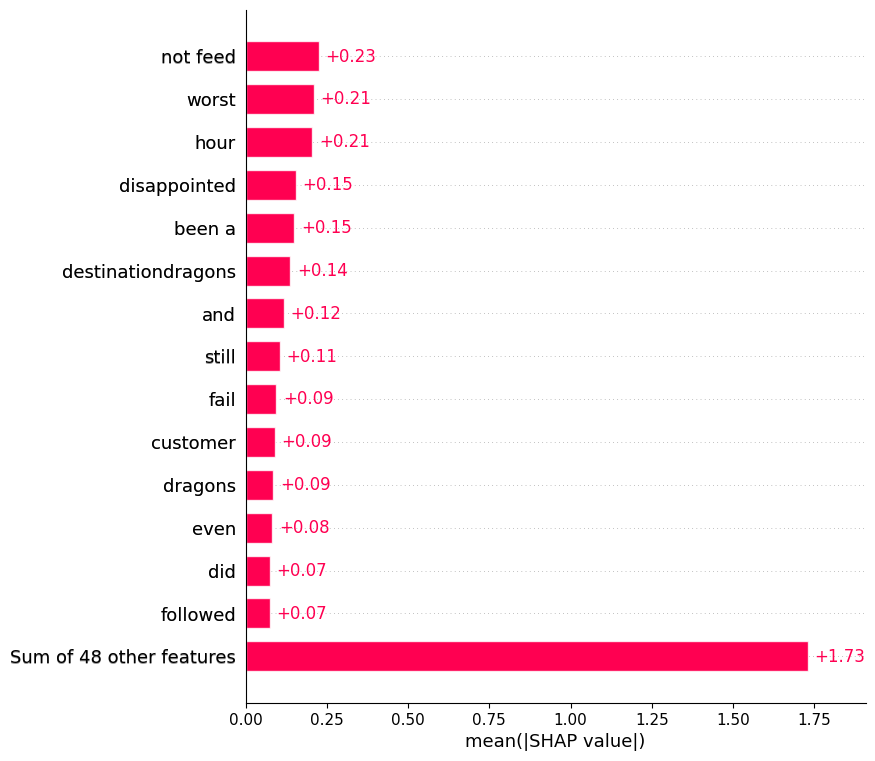

In [101]:
shap.plots.bar(
    shap_values[:, :, 0],
    max_display=15
)

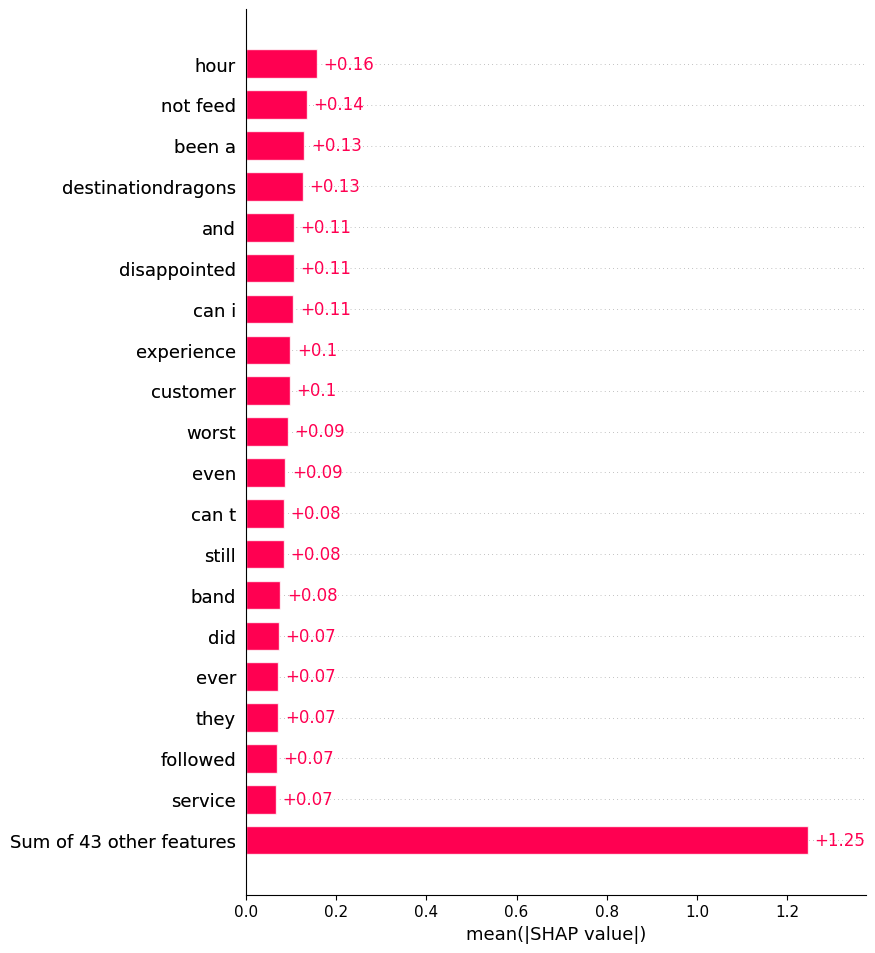

In [102]:
shap.plots.bar(
    shap_values[:, :, 1],
    max_display=20
)

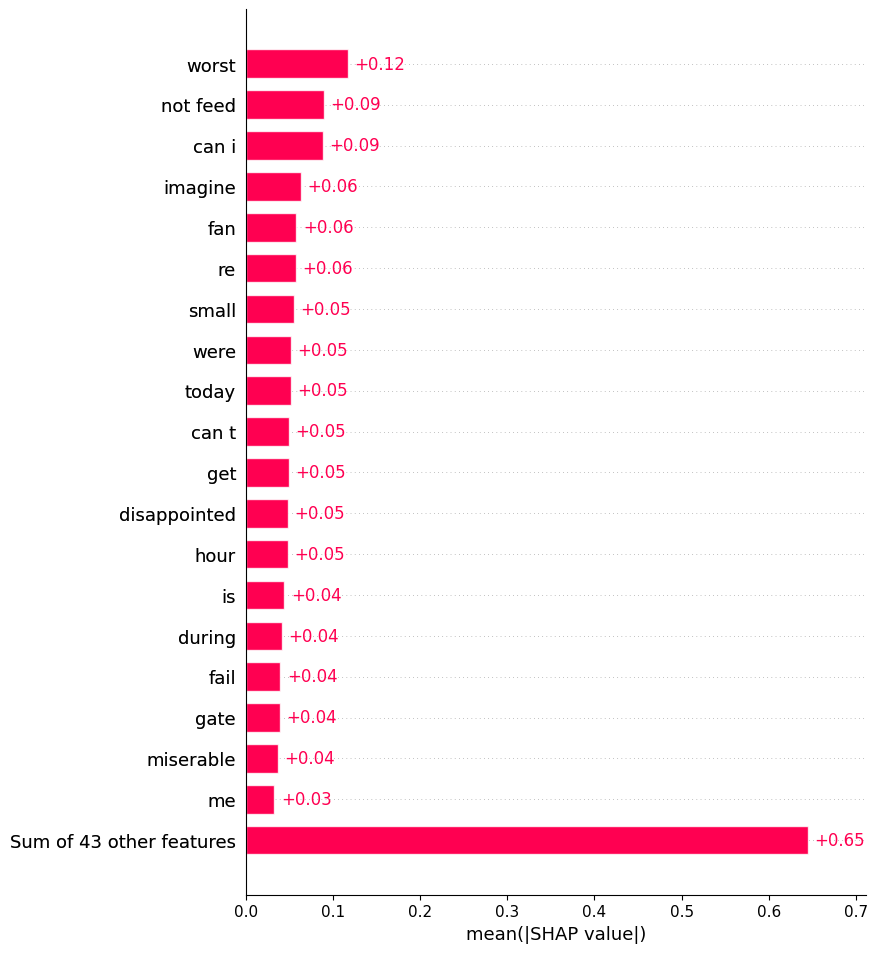

In [103]:
shap.plots.bar(
    shap_values[:, :, 2],
    max_display=20
)

exporting data for power BI

In [104]:
topic_output = negative_df.copy()

topic_output["topic"] = topics

topic_output.to_csv(
    "outputs/powerbi_topics.csv",
    index=False
)